# Experiment: Gesture Classification with Deep Learning

In this experiment, a neural network model is trained with EMG data from the 65HDsEMG database to classify gestures. Here, a subset of the EMG channels is used to have the configuration/organization of that of the armband developed for this project. The data are divided into training and validation data to train the model, and into test data to evaluate the classification performance of the trained model.

# Signal preprocessing

The folowing 4-step preprocessing is applied to the EMG signal data:
1. Rectification
2. Teager-Kaiser Energy Operator (TKE)
3. Moving Average (30 samples)
4. Normalization

The normalization step is applied during the training while the other ones have already been applied to the data. 

## Table of Contents

- [0. Import libraries](#0)
- [1. Config Variables and hyperparameters](#1)
- [2. Load dataset with dataloader](#2)
- [3. Create model to train](#3)
- [4. Training](#4)
- [5. Evaluate best model](#5)
- [6. Save the model in .H5 file](#6)


<a name="0"></a>
# Import Libraries

In [1]:
import os, sys

processing_source_path = os.path.abspath('./../../../Processing/')
if(processing_source_path not in sys.path):
    sys.path.append(processing_source_path)
import ProcessingPipeline as pp

dataloader_source_path = os.path.abspath('./../../../Dataloader/')
if(dataloader_source_path not in sys.path):
    sys.path.append(dataloader_source_path)
from EMGGestureDataGen import EMGGestureDataGen

dataloader_source_path = os.path.abspath('./../../../Dataloader/')
if(dataloader_source_path not in sys.path):
    sys.path.append(dataloader_source_path)
from EMGGestureDataGen import EMGGestureDataGen
from KerasDataPipeline import KerasDataPipeline

model_source_path = os.path.abspath('./../../../Keras_deep_models/')
if(model_source_path not in sys.path):
    sys.path.append(model_source_path)
from EMGConv2DResNetModel import EMGConv2DResNetModel

dataloader_source_path = os.path.abspath('./../../../Utils/')
if(dataloader_source_path not in sys.path):
    sys.path.append(dataloader_source_path)
import utils as utils
import available_metrics as metrics

In [2]:
import numpy as np
from os.path import join
import datetime
import matplotlib.pyplot as plt
import pandas as pd
import json

In [3]:
import tensorflow as tf
'''
# Get list of all physically available GPUs
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    try:
        # Force TensorFlow to only use the second physical GPU (index 1)
        tf.config.set_visible_devices(gpus[7], 'GPU')
        logical_gpus = tf.config.list_logical_devices('GPU')
        print(f"Active Logical GPUs: {len(logical_gpus)}")
    except RuntimeError as e:
        # Visible devices must be modified before GPUs are initialized
        print(e)
'''
import tensorflow as tf
print(tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
  try:
    # Currently, memory growth needs to be the same across GPUs
    for gpu in gpus:
      tf.config.experimental.set_memory_growth(gpu, True)
    logical_gpus = tf.config.list_logical_devices('GPU')
    print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
  except RuntimeError as e:
    # Memory growth must be set before GPUs have been initialized
    print(e)


2.9.1
8 Physical GPUs, 8 Logical GPUs


2026-09-01 00:13:06.486058: I tensorflow/core/platform/cpu_feature_guard.cc:194] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE3 SSE4.1 SSE4.2 AVX
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-09-01 00:13:10.726259: I tensorflow/core/common_runtime/gpu/gpu_process_state.cc:222] Using CUDA malloc Async allocator for GPU: 0
2026-09-01 00:13:10.726481: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1532] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 61957 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:07:00.0, compute capability: 8.0
2026-09-01 00:13:10.730598: I tensorflow/core/common_runtime/gpu/gpu_process_state.cc:222] Using CUDA malloc Async allocator for GPU: 1
2026-09-01 00:13:10.730668: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1532] Created device /job:localh

<a name="1"></a>
# Config Variables and hyperparameters

In [4]:
# model_name = 'EMG65_2D_CNN_multiclass_armband_onesubject20230627_194533'
model_name = None

In [5]:
def _cbeb_data_root():
    """Processed and raw datasets live in <package>/data, or CBEB_DATA_ROOT."""
    import os
    from pathlib import Path
    env = os.environ.get("CBEB_DATA_ROOT")
    if env:
        return Path(env).resolve()
    pkg = Path.cwd().resolve()
    for _ in range(8):
        if (pkg / "README.md").exists() and (pkg / "EMG").exists():
            return (pkg / "data").resolve()
        if pkg.parent == pkg:
            break
        pkg = pkg.parent
    return (Path.cwd().resolve() / "data").resolve()

if model_name is None:
    print('Crate new config model')
    data_params = {
        "checkpoint_path": "trainings/",
        "database_path": "65HD_gestures_common", #"65HD_gestures_comparison2_balanced",
        "training_name": 'EMG65_2D_CNN_multiclass_armband' + datetime.datetime.now().strftime("%Y%m%d_%H%M%S"),
        "img_width": 16,
        "img_height": 8,
        "num_features": 256, #num_samples
        "window_step": 12,
        'armband': False,
        'norm':1, # by sample, each time between the channels
    }
    training_params = {
        "early_stopping_patient": 10,
        "epochs": 200,
        "batch_size": 256,
        "lr": 0.01,
        "loss": 'SparceCatCE',
        "filter_divisor": 4,
    }
    optimizer = tf.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True)
    model_params = {
        "model_output_mode": 'multiclass',
        "print_model": True,
        #"network_name": 'EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_SGD',
        #"optimizer": optimizer._name,
        "network_name": 'EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW',
        "optimizer": 'adamW',
        "channels": 128,
    }
    # Combine all categories into a single dictionary
    config_model = {**data_params, **model_params, **training_params}
    
    try:
        with open(join(str(_cbeb_data_root() / config_model['database_path']), 'train', 'dataset_param.json')) as json_file:
            dataset_param = json.load(json_file)
            config_model['num_classes'] = len(dataset_param['dataset']['gestures'])
    except:
         config_model['num_classes'] = 7
else:
    config_path = join('trainings/', model_name, 'training_param.json')
    print('Loading config model from:', config_path)
    with open(config_path) as json_file:
        config_model = json.load(json_file)
    
print(config_model)


Crate new config model
{'checkpoint_path': 'trainings/', 'database_path': '65HD_gestures_common', 'training_name': 'EMG65_2D_CNN_multiclass_armband20260901_001310', 'img_width': 16, 'img_height': 8, 'num_features': 256, 'window_step': 12, 'armband': False, 'norm': 1, 'model_output_mode': 'multiclass', 'print_model': True, 'network_name': 'EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW', 'optimizer': 'adamW', 'channels': 128, 'early_stopping_patient': 10, 'epochs': 200, 'batch_size': 256, 'lr': 0.01, 'loss': 'SparceCatCE', 'filter_divisor': 4, 'num_classes': 12}


In [6]:
# Data root: download raw/preprocessed data under <package>/data (see docs/DATASETS.md)
# or export CBEB_DATA_ROOT=/path/to/data
from pathlib import Path as _Path
import os as _os
_pkg = _Path.cwd().resolve()
for _ in range(8):
    if (_pkg / "README.md").exists() and (_pkg / "EMG").exists():
        break
    _pkg = _pkg.parent
_DATA_ROOT = _Path(_os.environ.get("CBEB_DATA_ROOT", _pkg / "data")).resolve()
dataset_path = str(_DATA_ROOT / config_model["database_path"])
num_gestures = config_model['num_classes']
window_size = config_model['num_features']
window_step = config_model['window_step']
img_width = config_model['img_width']
img_height = config_model['img_height']
batch_size = config_model['batch_size']
num_emg_channels = config_model['channels']
armband= config_model['armband']


In [7]:
try:
    with open(join(dataset_path, 'train', 'dataset_param.json')) as json_file:
        dataset_param = json.load(json_file)
        gesture_list = dataset_param['dataset']['gestures']
        print(dataset_param)
except:
    #gesture_list =[0, 13, 14, 17, 20, 36, 58, 59, 63, 64]
    with open('../../../DataBase_Treatment/gestures_comparison_65HD_Hyser.json', 'r', encoding='utf-8') as f:
        gestures = json.load(f)
    gesture_names = [g['hdemg_label'] for g in gestures['gesture_mapping']]
    gesture_list = [int(g['hdemg_id']) for g in gestures['gesture_mapping']]
    print(gesture_names)
    #print(glob.glob(join(dataset_path, 'train/*')))
gesture_list, len(gesture_list)

{'name': '65HDsEMG_20260831_190813', 'dataset': {'name': '65HDsEMG', 'preprocessing': ['SampleTrimmer(1,1024,1024)', 'Retification', 'EMGTKE', 'MAFilter(31)'], 'force_preprocessing': ['SampleTrimmer(1,1055,1025)'], 'subject': ['25312382', '25313324', 'test', '25313078', '25309355', '25295423', '25323215', 'unique', '25323257', '.ipynb_checkpoints', '25323134', '25296788', '24350114', '25296644', '25323104', '25313597', '25323065', '25313726', '25312253', '25295225'], 'session': [0], 'gestures': [0, 10, 8, 6, 4, 2, 13, 14, 15, 16, 61, 58], 'repetition': [1, 3, 5], 'rest_repetition': 3}}


([0, 10, 8, 6, 4, 2, 13, 14, 15, 16, 61, 58], 12)

In [8]:
config_model['gesture_list'] = gesture_list
config_model['num_classes'] = len(gesture_list)

<a name="2"></a>
# Load dataset with dataloader

In [9]:
num_emg_channels

128

In [10]:
data_processing = pp.ProcessingPipeline([
    pp.NormMinMax(axis=config_model['norm']), # initial shape: (batchsize, img_width*img_height, samples)
    pp.DataReshape((img_width, img_height, window_size)),
    #pp.LabelOneHot(np.sort(gesture_list)) # to multiclass 
    ])

train_dataset = EMGGestureDataGen(join(dataset_path, 'train/'), batch_size, window_size, window_step, num_emg_channels, processing=data_processing, armband=armband, dataset_name=config_model['database_path'])
val_dataset = EMGGestureDataGen(join(dataset_path, 'val/'), batch_size, window_size, window_step, num_emg_channels, processing=data_processing, armband=armband, dataset_name=config_model['database_path'])
test_dataset = EMGGestureDataGen(join(dataset_path, 'test/'), batch_size, window_size, window_step, num_emg_channels, processing=data_processing, armband=armband, dataset_name=config_model['database_path'])

In [11]:
train_dataset[0][0].shape

(256, 16, 8, 256)

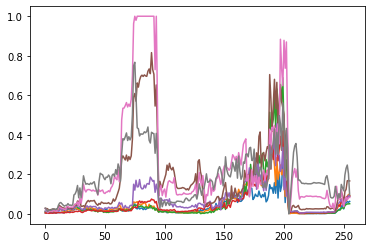

In [12]:
plt.plot(train_dataset[0][0][0,0,:].T)
plt.show()

In [13]:
np.unique(val_dataset[0][1])

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])

In [14]:
# # UNCOMMENT TO USE CLASS WEIGHTS
# from sklearn.utils import class_weight

# class_weights = class_weight.compute_class_weight('balanced', classes=np.arange(len(gesture_list)), y=train_dataset.yData)
# config_model['class_weights'] = dict(enumerate(class_weights))

In [15]:
#train_dataset_pipeline = KerasDataPipeline(train_dataset, (None, img_width, img_height, window_size), [None, config_model['num_classes']])
#val_dataset_pipeline = KerasDataPipeline(val_dataset, (None, img_width, img_height, window_size), [None, config_model['num_classes']])

In [16]:
train_dataset_pipeline = KerasDataPipeline(train_dataset, (None, img_width, img_height, window_size), [None, ])
val_dataset_pipeline = KerasDataPipeline(val_dataset, (None, img_width, img_height, window_size), [None, ])

<a name="3"></a>
# Create model to train

In [17]:
emg_model = EMGConv2DResNetModel(config_model)
emg_model.load_model()

path False
model compiled
Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 16, 8, 256)  0           []                               
                                ]                                                                 
                                                                                                  
 conv2d (Conv2D)                (None, 16, 8, 32)    73760       ['input_1[0][0]']                
                                                                                                  
 batch_normalization (BatchNorm  (None, 16, 8, 32)   128         ['conv2d[0][0]']                 
 alization)                                                                                       
                                                                    

<a name="4"></a>
# Training

In [18]:
history = emg_model.train(train_dataset_pipeline.datasetPipeline, val_dataset_pipeline.datasetPipeline)

#with open(join(config_model['checkpoint_path'], config_model['network_name'], 'training_param.json'), 'w') as fp:
#    json.dump(config_model, fp, indent=4)

no weights
trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW
Epoch 1/200


2026-09-01 00:14:33.536569: I tensorflow/stream_executor/cuda/cuda_dnn.cc:424] Loaded cuDNN version 8500
2026-09-01 00:14:34.327832: I tensorflow/stream_executor/cuda/cuda_blas.cc:1804] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.


INFO:tensorflow:Assets written to: trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW/assets


INFO:tensorflow:Assets written to: trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW/assets


1869/1869 - 240s - loss: 0.4358 - accuracy: 0.8547 - val_loss: 1.1956 - val_accuracy: 0.7695 - 240s/epoch - 129ms/step
Epoch 2/200


INFO:tensorflow:Assets written to: trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW/assets


... (7 outputs left out)

1869/1869 - 200s - loss: 0.1046 - accuracy: 0.9663 - val_loss: 0.1792 - val_accuracy: 0.9614 - 200s/epoch - 107ms/step
Epoch 7/200


INFO:tensorflow:Assets written to: trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW/assets


INFO:tensorflow:Assets written to: trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW/assets


1869/1869 - 196s - loss: 0.0967 - accuracy: 0.9686 - val_loss: 0.1561 - val_accuracy: 0.9632 - 196s/epoch - 105ms/step
Epoch 8/200
1869/1869 - 194s - loss: 0.0917 - accuracy: 0.9701 - val_loss: 0.1703 - val_accuracy: 0.9655 - 194s/epoch - 104ms/step
Epoch 9/200
1869/1869 - 196s - loss: 0.0861 - accuracy: 0.9720 - val_loss: 0.1943 - val_accuracy: 0.9601 - 196s/epoch - 105ms/step
Epoch 10/200
1869/1869 - 197s - loss: 0.0826 - accuracy: 0.9730 - val_loss: 0.1765 - val_accuracy: 0.9625 - 197s/epoch - 105ms/step
Epoch 11/200
1869/1869 - 197s - loss: 0.0774 - accuracy: 0.9747 - val_loss: 0.1906 - val_accuracy: 0.9630 - 197s/epoch - 105ms/step
Epoch 12/200
1869/1869 - 195s - loss: 0.0754 - accuracy: 0.9754 - val_loss: 0.2376 - val_accuracy: 0.9527 - 195s/epoch - 104ms/step
Epoch 13/200
1869/1869 - 196s - loss: 0.0730 - accuracy: 0.9761 - val_loss: 0.1907 - val_accuracy: 0.9633 - 196s/epoch - 105ms/step
Epoch 14/200
1869/1869 - 196s - loss: 0.0703 - accuracy: 0.9769 - val_loss: 0.1599 - val_ac

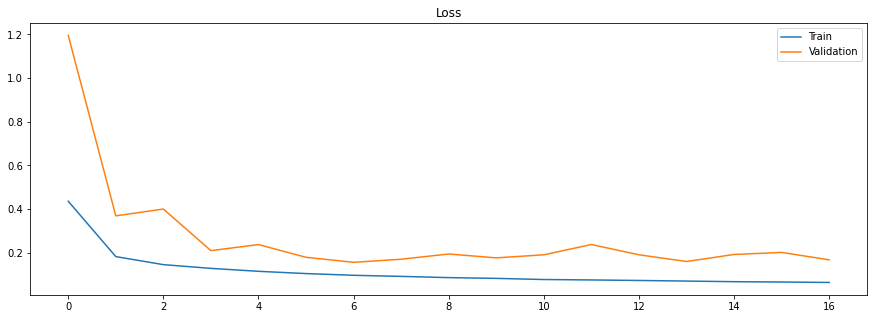

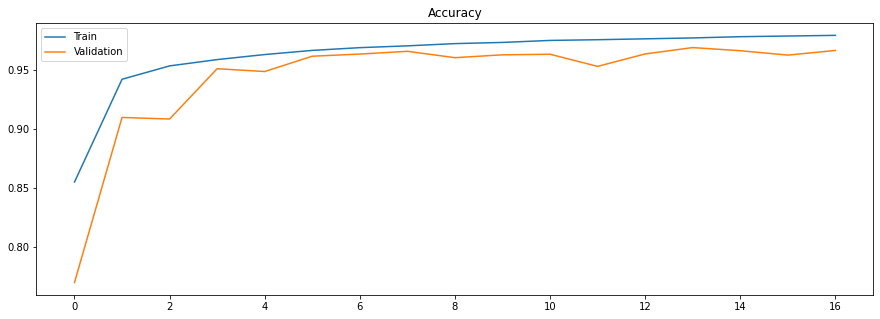

In [19]:
from pandas import read_csv
import matplotlib.pyplot as plt

plt.figure(figsize=(15,5))
plt.title("Loss")
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.legend()

plt.figure(figsize=(15,5))
plt.title("Accuracy")
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.legend()

<a name="5"></a>
# Evaluate best model

In [20]:
import tensorflow_addons as tfa
# load best model
trained_deep_model = tf.keras.models.load_model(join(config_model['checkpoint_path'] + config_model['network_name']))

<a name="5-1"></a>
### Train Dataset

In [21]:
test_performance = trained_deep_model.evaluate(train_dataset)
y_train, y_pred = utils.generate_data(train_dataset, trained_deep_model)

1869/1869 [==============================] - 167s 89ms/step - loss: 0.0296 - accuracy: 0.9894


  0% 0/1869 [00:00<?, ?it/s]

8/8 [==============================] - 0s 16ms/step


  0% 1/1869 [00:00<16:48,  1.85it/s]

8/8 [==============================] - 0s 2ms/step


  0% 2/1869 [00:00<11:15,  2.77it/s]

... (3,730 outputs left out)

8/8 [==============================] - 0s 2ms/step


100% 1868/1869 [07:11<00:00,  4.60it/s]

8/8 [==============================] - 0s 2ms/step


100% 1869/1869 [07:11<00:00,  4.33it/s]


In [22]:
pr, re, f1, acc=metrics.model_metrics(config_model['gesture_list'] ,y_train, y_pred, Get_metrics=True) 

              precision    recall  f1-score   support

           0       0.99      0.99      0.99    127626
          10       1.00      0.99      1.00     30940
           8       0.95      1.00      0.97     31440
           6       0.98      0.99      0.99     30906
           4       0.99      0.98      0.99     32704
           2       1.00      0.98      0.99     33058
          13       0.99      0.99      0.99     31509
          14       0.99      0.99      0.99     32609
          15       1.00      0.99      1.00     31643
          16       1.00      1.00      1.00     31656
          61       1.00      0.97      0.99     31626
          58       1.00      1.00      1.00     32747

    accuracy                           0.99    478464
   macro avg       0.99      0.99      0.99    478464
weighted avg       0.99      0.99      0.99    478464



/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1298: UserWarning: Note that pos_label (set to 'positive') is ignored when average != 'binary' (got 'macro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn("Note that pos_label (set to %r) is ignored when "


Precision Score:  0.9903187610967965


/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1298: UserWarning: Note that pos_label (set to 'positive') is ignored when average != 'binary' (got 'macro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn("Note that pos_label (set to %r) is ignored when "


Recall Score:  0.9894600529128149
F1-Score:  0.9898128402635061
Accuracy:  0.9893638810861424


In [23]:
config_model['gesture_list']


[0, 10, 8, 6, 4, 2, 13, 14, 15, 16, 61, 58]

In [24]:
index1 = np.append(np.arange(8),np.arange(8))
index1 = np.append(index1,index1)
index1 = np.append(index1,index1)

index2 = np.repeat(np.arange(8),4)
index2 = np.append(index2,np.roll(index2,-4))

In [25]:
index1[:7]

array([0, 1, 2, 3, 4, 5, 6])

In [26]:
index2[:7]

array([0, 0, 0, 0, 1, 1, 1])

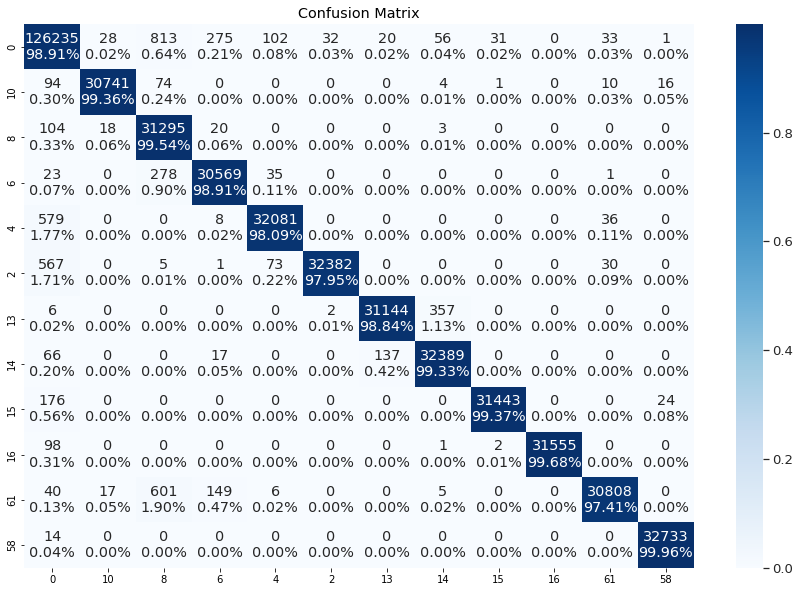

In [27]:
# available the train data 
cfm_deep_model=metrics.plot_confusion_matrix(config_model['gesture_list'], y_train, y_pred, Get_matrix=True)

<a name="5-2"></a>
### Test Dataset

In [28]:
test_performance = trained_deep_model.evaluate(test_dataset)
y_test, y_pred = utils.generate_data(test_dataset, trained_deep_model)

963/963 [==============================] - 97s 100ms/step - loss: 0.1163 - accuracy: 0.9713


  0% 0/963 [00:00<?, ?it/s]

8/8 [==============================] - 0s 2ms/step


  0% 1/963 [00:00<03:38,  4.40it/s]

8/8 [==============================] - 0s 2ms/step


  0% 2/963 [00:00<03:33,  4.50it/s]

... (1,918 outputs left out)

8/8 [==============================] - 0s 2ms/step


100% 962/963 [03:47<00:00,  4.41it/s]

8/8 [==============================] - 0s 2ms/step


100% 963/963 [03:47<00:00,  4.24it/s]


In [29]:
pr, re, f1, acc=metrics.model_metrics(config_model['gesture_list'] ,y_test, y_pred, Get_metrics=True) 

              precision    recall  f1-score   support

           0       0.98      0.98      0.98    128123
          10       0.99      0.97      0.98     10387
           8       0.94      0.91      0.93     10513
           6       0.91      0.97      0.94     10704
           4       0.99      0.97      0.98     11272
           2       0.97      0.99      0.98     11222
          13       1.00      0.96      0.98     10744
          14       0.94      0.98      0.96     10437
          15       0.94      0.94      0.94     11268
          16       0.97      0.99      0.98     11052
          61       0.94      0.96      0.95     10093
          58       0.97      0.98      0.98     10713

    accuracy                           0.97    246528
   macro avg       0.96      0.97      0.96    246528
weighted avg       0.97      0.97      0.97    246528

Precision Score:  0.9619323408315129


/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1298: UserWarning: Note that pos_label (set to 'positive') is ignored when average != 'binary' (got 'macro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn("Note that pos_label (set to %r) is ignored when "
/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1298: UserWarning: Note that pos_label (set to 'positive') is ignored when average != 'binary' (got 'macro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn("Note that pos_label (set to %r) is ignored when "


Recall Score:  0.9655157844691359
F1-Score:  0.963492044348313
Accuracy:  0.9712730399792315


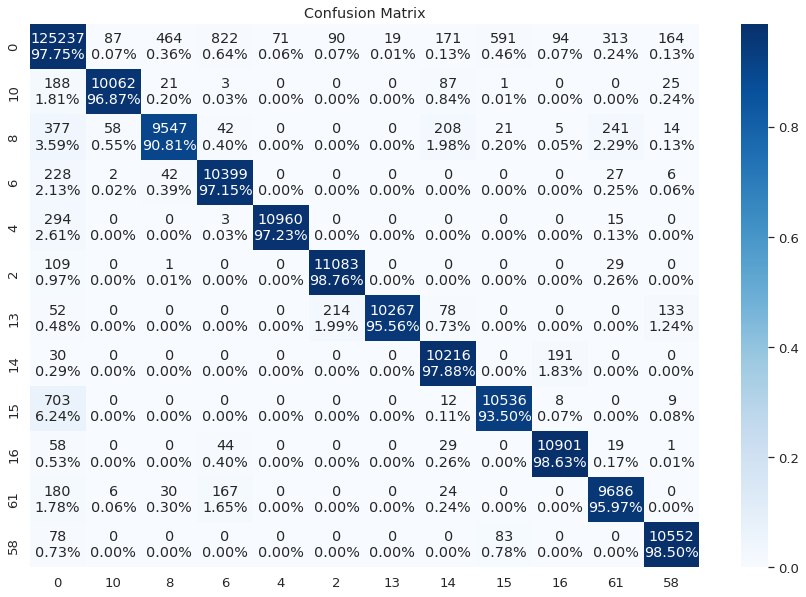

In [30]:
# available the test data 
cfm_deep_model=metrics.plot_confusion_matrix(config_model['gesture_list'], y_test, y_pred, Get_matrix=True)

#### Metrics with Average and std for each classes

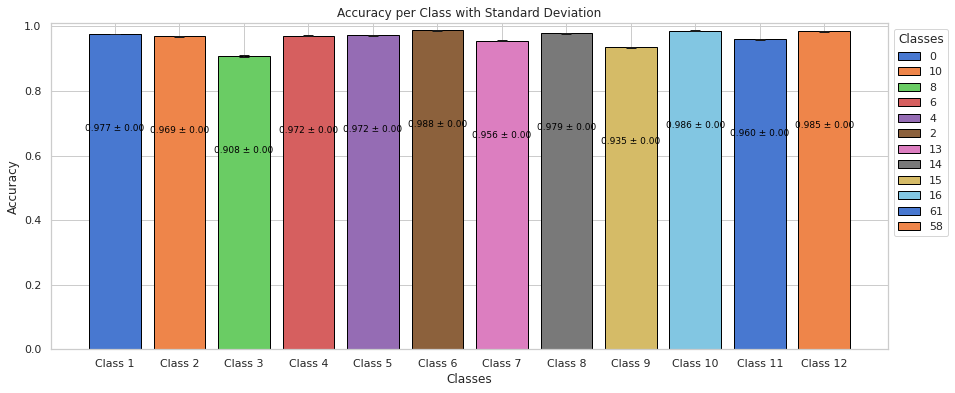

In [31]:
metrics.plot_metric_per_class(cfm_deep_model, config_model['gesture_list'], metric_name='Accuracy', method='per_class')

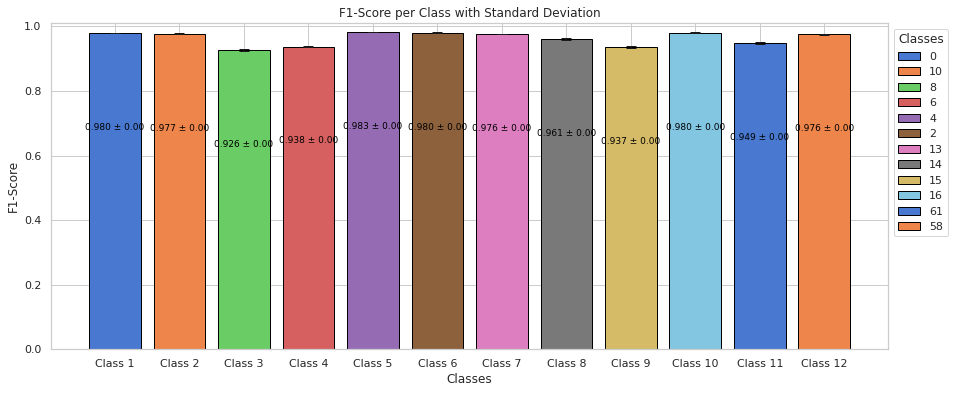

In [32]:
metrics.plot_metric_per_class(cfm_deep_model, config_model['gesture_list'], metric_name='F1-Score', method='per_class')

#### Mean and std for all Classes 

In [33]:
metrics_per_class,precision_list,recall_list,f1_score_list,accuracy_list=metrics.model_average_std_metrics(cf_matrix=cfm_deep_model, Get_metrics=True, Verbose=True) 

Precision Score: 0.9619±0.0266
Recall Score: 0.9655±0.0225
F1-Score: 0.9635±0.0198
Accuracy: 0.9655±0.0225


In [34]:
metrics_average_and_std_df=pd.DataFrame(data=[precision_list,recall_list,f1_score_list,accuracy_list],
             index=['pr', 're', 'f1', 'acc'],
             columns=['Average','std'])
metrics_average_and_std_df

,Average,std
pr,0.961932,0.026574
re,0.965516,0.022489
f1,0.963492,0.019849
acc,0.965516,0.022489


## ROC

ROC AUC for Class 0: 0.97904
ROC AUC for Class 1: 0.98403
ROC AUC for Class 2: 0.95287
ROC AUC for Class 3: 0.98346
ROC AUC for Class 4: 0.98601
ROC AUC for Class 5: 0.99316
ROC AUC for Class 6: 0.97776
ROC AUC for Class 7: 0.98812
ROC AUC for Class 8: 0.96604
ROC AUC for Class 9: 0.99254
ROC AUC for Class 10: 0.97848
ROC AUC for Class 11: 0.99174


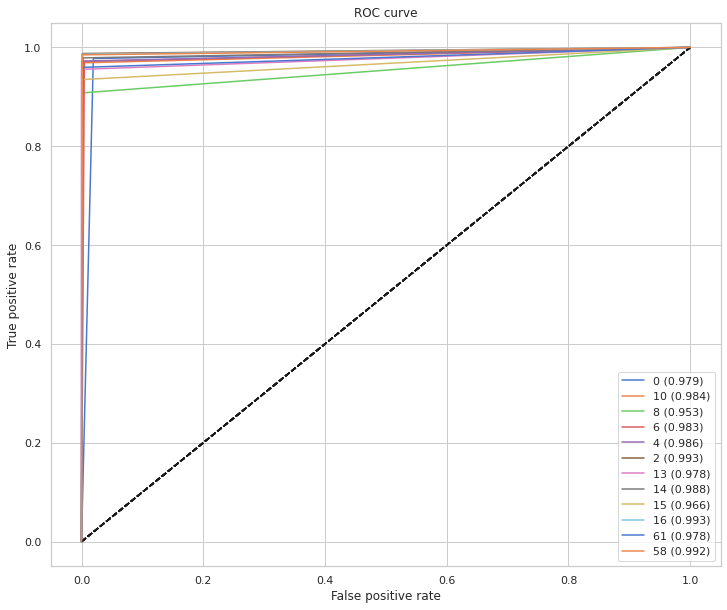

In [35]:
roc_score_per_class=metrics.get_roc_curve(config_model['gesture_list'], y_test, y_pred ,verbose=True)

In [36]:
# import mlflow_save_parameters_multiclass 

# mlflow_save_parameters_multiclass.save_data_in_mlflow("65HDsEMG_multiclass_armband", config_model, test_metric, data_processing.getProcessingNameList())

<a name="6"></a>
## Save the model in .H5 file

In [37]:
trained_deep_model.save(config_model['checkpoint_path'] +  config_model['network_name']+'/ResNet2D.h5')

In [38]:
config_model['checkpoint_path'] +  config_model['network_name']+'/ResNet2D.h5'

'trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW/ResNet2D.h5'